## Cell subsampling using TopACeDo

In [1]:
%load_ext autotime

import scarf
scarf.__version__

'0.32.4'

time: 2.77 s (started: 2026-10-12 11:45:33 +02:00)


---
### 1) Installing dependencies

We need to install the TopACeDo algorithm to perform subsampling:

```bash
uv pip install topacedo
```

---
### 2) Fetching pre-processed data

In [2]:
# Loading preanalyzed dataset that was processed in the `basic_tutorial` vignette
scarf.fetch_dataset(
    dataset_name='tenx_5K_pbmc_rnaseq',
    as_zarr=True, 
    save_path='scarf_datasets'
)

time: 30.3 s (started: 2026-10-12 11:45:36 +02:00)


/home/parashar/scarf/scarf/plots.py:597: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  centers = df[[x, y, vc]].groupby(vc).median().T


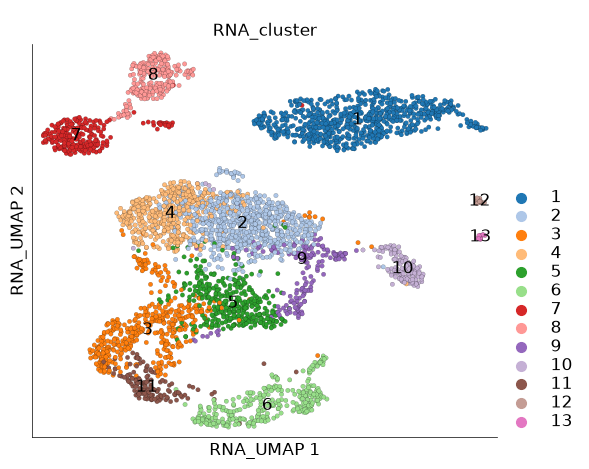

time: 4.58 s (started: 2026-10-12 11:46:05 +02:00)


In [3]:
ds = scarf.DataStore('scarf_datasets/tenx_5K_pbmc_rnaseq/data.zarr')

ds.plot_layout(
    layout_key='RNA_UMAP',
    color_by='RNA_cluster'
)

---
### 3) Run TopACeDo downsampler

UMAP, clustering and marker identification together allow a good understanding of cellular diversity. However, one can still choose from a plethora of other analysis on the data. For example, identification of cell differentiation trajectories. One of the major challenges to run these analysis could be the size of the data. Scarf performs a topology conserving downsampling of the data based on the cell neighbourhood graph. This downsampling aims to maximize the heterogeneity while sampling cells from the data.

Here we run the TopACeDo downsampling algorithm that leverages Scarf's KNN graph to perform a manifold preserving subsampling of cells. The subsampler can be invoked directly from Scarf's DataStore object.

In [4]:
ds.run_topacedo_sampler(
    cluster_key='RNA_cluster',
    max_sampling_rate=0.1
)

Constructing graph from dendrogram:   0%|          | 0/3939 [00:00<?, ?it/s]

Constructing graph from dendrogram:  70%|███████   | 2761/3939 [00:00<00:00, 27605.48it/s]

Constructing graph from dendrogram: 100%|██████████| 3939/3939 [00:00<00:00, 30712.85it/s]

INFO: 384 cells (9.75%) sub-sampled. Subsample to Seed (165 cells) ratio: 2.327


time: 9.46 s (started: 2026-10-12 11:46:10 +02:00)


As a result of subsampling the subsampled cells are marked True under the cell metadata column `RNA_sketched`. We can visualize these cells using `plot_layout`

/home/parashar/scarf/scarf/plots.py:597: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  centers = df[[x, y, vc]].groupby(vc).median().T


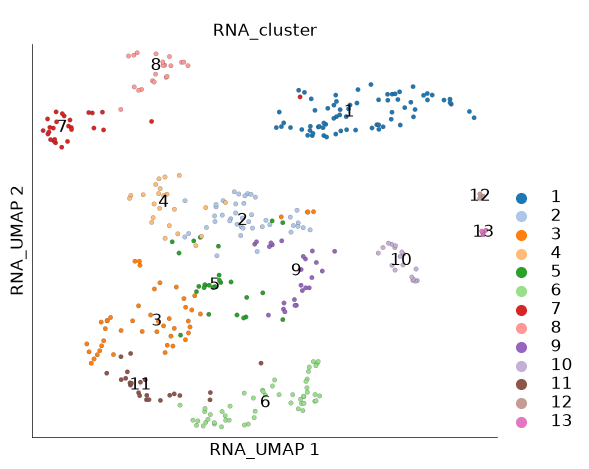

time: 867 ms (started: 2026-10-12 11:46:18 +02:00)


In [5]:
ds.plot_layout(
    layout_key='RNA_UMAP',
    color_by='RNA_cluster',
    subselection_key='RNA_sketched'
)

It may also be interesting to visualize the cells that were marked as `seed cells` used when PCST was run. These cells are marked under the column `RNA_sketch_seeds`.

/home/parashar/scarf/scarf/plots.py:597: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  centers = df[[x, y, vc]].groupby(vc).median().T


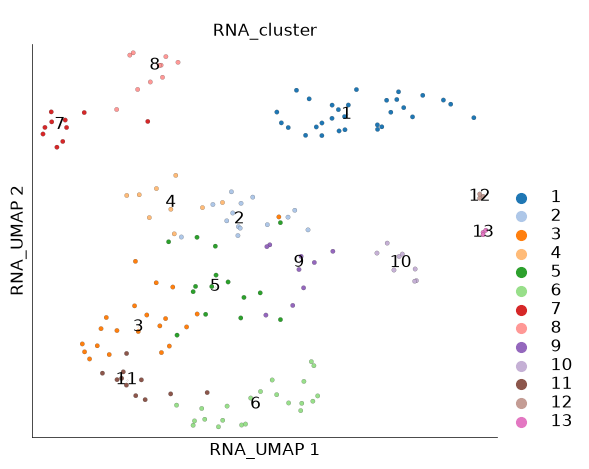

time: 952 ms (started: 2026-10-12 11:46:19 +02:00)


In [6]:
ds.plot_layout(
    layout_key='RNA_UMAP',
    color_by='RNA_cluster', 
    subselection_key='RNA_sketch_seeds'
)

---
### 4) Intermediate parameters of downsampling

To identify the seed cells, the subsampling algorithm calculates cell densities based on neighbourhood degrees. Regions of higher cell density get a sampling penalty. The neighbourhood degree of individual cells are stored under the column `RNA_cell_density`.

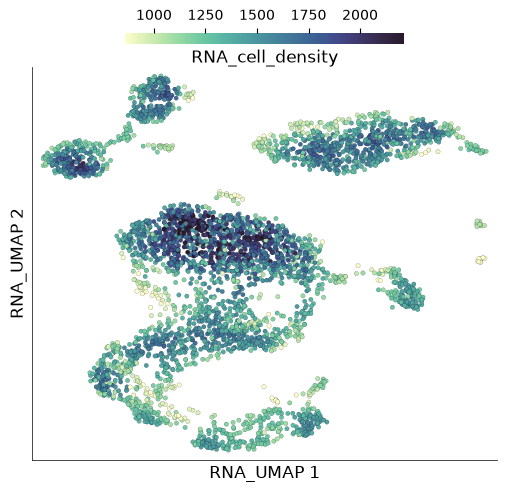

time: 1.14 s (started: 2026-10-12 11:46:20 +02:00)


In [7]:
ds.plot_layout(
    layout_key='RNA_UMAP',
    color_by='RNA_cell_density'
)

The dowsampling algorithm also identifies regions of the graph where cells form tightly connected groups by calculating mean shared nearest neighbours of each cell's nieghbours. The tightly connected regions get a sampling award. These values can be accessed from under the cell metadata column `RNA_snn_value`.

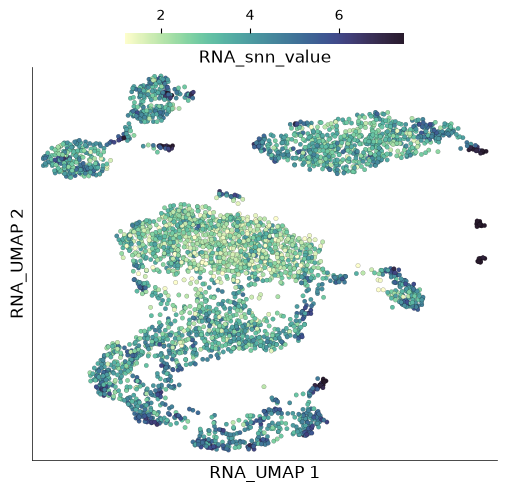

time: 997 ms (started: 2026-10-12 11:46:21 +02:00)


In [8]:
ds.plot_layout(
    layout_key='RNA_UMAP',
    color_by='RNA_snn_value'
)

---
### 5) Exporting downsampled data

TopACeDo only marks the cells the representative that for downsampling. To create a new subsampled datasets, `SubsetZarr` writer class must be used. This will create a new Zarr file containing only the subset of cells.

In [9]:
writer = scarf.SubsetZarr(
    zarr_loc='scarf_datasets/tenx_5K_pbmc_rnaseq/subset.zarr',
    assays=[ds.RNA],
    cell_key='RNA_sketched',
    reset_cell_filter=False
)
writer.dump()

Subsetting assay: RNA:   0%|                                                                                  …

time: 3.21 s (started: 2026-10-12 11:46:22 +02:00)


The downsampled dataset can be loaded as a new DataStore

In [10]:
ds2 = scarf.DataStore('scarf_datasets/tenx_5K_pbmc_rnaseq/subset.zarr')

(RNA) Computing nCells and dropOuts:   0%|                                                                    …

(RNA) Computing RNA_percentMito:   0%|                                                                        …

(RNA) Computing RNA_percentRibo:   0%|                                                                        …

time: 2.37 s (started: 2026-10-12 11:46:26 +02:00)


In [11]:
ds2

DataStore has 384 (384) cells with 1 assays: RNA
   Cell metadata:
            'I', 'ids', 'names', 'RNA_UMAP1', 'RNA_UMAP2', 
            'RNA_cell_density', 'RNA_cluster', 'RNA_leiden_cluster', 'RNA_nCounts', 'RNA_nFeatures', 
            'RNA_percentMito', 'RNA_percentRibo', 'RNA_sketch_seeds', 'RNA_sketched', 'RNA_snn_value', 
            'RNA_tSNE1', 'RNA_tSNE2'
   RNA assay has 8773 (33538) features and following metadata:
            'I', 'ids', 'names', 'dropOuts', 'nCells', 
          

time: 39.5 ms (started: 2026-10-12 11:46:28 +02:00)


It is expected the downsampled dataset will be small enough to fit in memory. Here the data is exported to  anndata format from where it could easily used to perform any downstream analysis from the [scverse](https://scverse.org/) ecosystem.

```bash
uv pip install anndata
```

In [12]:
adata = ds2.to_anndata()

INFO: Converting raw data from RNA assay into CSR format:   0%|                                               …

time: 1.94 s (started: 2026-10-12 11:46:28 +02:00)


In [13]:
adata

AnnData object with n_obs × n_vars = 384 × 33538
    obs: 'I', 'names', 'RNA_UMAP1', 'RNA_UMAP2', 'RNA_cell_density', 'RNA_cluster', 'RNA_leiden_cluster', 'RNA_nCounts', 'RNA_nFeatures', 'RNA_percentMito', 'RNA_percentRibo', 'RNA_sketch_seeds', 'RNA_sketched', 'RNA_snn_value', 'RNA_tSNE1', 'RNA_tSNE2'
    var: 'I', 'names', 'dropOuts', 'nCells'

time: 4.3 ms (started: 2026-10-12 11:46:30 +02:00)


---
That is all for this vignette.